In [143]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("elikplim/eergy-efficiency-dataset")

print("Path to dataset files:", path)

Path to dataset files: /home/aditya0oo0/.cache/kagglehub/datasets/elikplim/eergy-efficiency-dataset/versions/1


In [144]:
raw_data = open("/home/aditya0oo0/.cache/kagglehub/datasets/elikplim/eergy-efficiency-dataset/versions/1/ENB2012_data.csv", 'r').readlines()[1:]
visited = []
for i in raw_data:
    if i not in visited:
        visited.append(i)        ### No duplication in data
raw_data = visited
del visited
raw_data[:2]

['0.98,514.50,294.00,110.25,7.00,2,0.00,0,15.55,21.33\n',
 '0.98,514.50,294.00,110.25,7.00,3,0.00,0,15.55,21.33\n']

In [145]:
import numpy as np
import torch
# filter the data

data = np.array([i[:-1].split(',') for i in raw_data], dtype=np.float32)   # makes ndarray from str
# del raw_data

n = int(0.9*data.shape[0])

train_data = torch.tensor(data[:n], dtype=torch.float32)
test_data = torch.tensor(data[n:], dtype=torch.float32)

train_data.shape, test_data

(torch.Size([691, 10]),
 tensor([[7.9000e-01, 6.3700e+02, 3.4300e+02, 1.4700e+02, 7.0000e+00, 5.0000e+00,
          4.0000e-01, 4.0000e+00, 4.2960e+01, 3.9560e+01],
         [7.6000e-01, 6.6150e+02, 4.1650e+02, 1.2250e+02, 7.0000e+00, 2.0000e+00,
          4.0000e-01, 4.0000e+00, 4.0680e+01, 4.0360e+01],
         [7.6000e-01, 6.6150e+02, 4.1650e+02, 1.2250e+02, 7.0000e+00, 3.0000e+00,
          4.0000e-01, 4.0000e+00, 4.0400e+01, 3.9670e+01],
         [7.6000e-01, 6.6150e+02, 4.1650e+02, 1.2250e+02, 7.0000e+00, 4.0000e+00,
          4.0000e-01, 4.0000e+00, 4.0600e+01, 3.9850e+01],
         [7.6000e-01, 6.6150e+02, 4.1650e+02, 1.2250e+02, 7.0000e+00, 5.0000e+00,
          4.0000e-01, 4.0000e+00, 4.0110e+01, 4.0770e+01],
         [7.4000e-01, 6.8600e+02, 2.4500e+02, 2.2050e+02, 3.5000e+00, 2.0000e+00,
          4.0000e-01, 4.0000e+00, 1.4370e+01, 1.6610e+01],
         [7.4000e-01, 6.8600e+02, 2.4500e+02, 2.2050e+02, 3.5000e+00, 3.0000e+00,
          4.0000e-01, 4.0000e+00, 1.4480e+01, 1.

In [146]:
# inputs and targets split

inputs = train_data[:, :-2]      
targets = train_data[:, -2:]

test_inputs = test_data[:, :-2]
test_targets = test_data[:, -2:]
inputs, targets, test_inputs, test_targets

(tensor([[9.8000e-01, 5.1450e+02, 2.9400e+02,  ..., 2.0000e+00, 0.0000e+00,
          0.0000e+00],
         [9.8000e-01, 5.1450e+02, 2.9400e+02,  ..., 3.0000e+00, 0.0000e+00,
          0.0000e+00],
         [9.8000e-01, 5.1450e+02, 2.9400e+02,  ..., 4.0000e+00, 0.0000e+00,
          0.0000e+00],
         ...,
         [7.9000e-01, 6.3700e+02, 3.4300e+02,  ..., 2.0000e+00, 4.0000e-01,
          4.0000e+00],
         [7.9000e-01, 6.3700e+02, 3.4300e+02,  ..., 3.0000e+00, 4.0000e-01,
          4.0000e+00],
         [7.9000e-01, 6.3700e+02, 3.4300e+02,  ..., 4.0000e+00, 4.0000e-01,
          4.0000e+00]]),
 tensor([[15.5500, 21.3300],
         [15.5500, 21.3300],
         [15.5500, 21.3300],
         ...,
         [42.7700, 38.3300],
         [41.7300, 47.5900],
         [41.3200, 46.2300]]),
 tensor([[7.9000e-01, 6.3700e+02, 3.4300e+02, 1.4700e+02, 7.0000e+00, 5.0000e+00,
          4.0000e-01, 4.0000e+00],
         [7.6000e-01, 6.6150e+02, 4.1650e+02, 1.2250e+02, 7.0000e+00, 2.0000e+00,
 

In [147]:
inputs_norm = torch.hstack([inputs[:, :4] / 1000, inputs[:, 4:]/10])
out_norms = targets

test_inputs_norm = torch.hstack([test_inputs[:, :4]/1000, test_inputs[:, 4:]/10])
test_out_norms = test_targets

inputs_norm, out_norms, test_inputs_norm, test_out_norms

(tensor([[0.0010, 0.5145, 0.2940,  ..., 0.2000, 0.0000, 0.0000],
         [0.0010, 0.5145, 0.2940,  ..., 0.3000, 0.0000, 0.0000],
         [0.0010, 0.5145, 0.2940,  ..., 0.4000, 0.0000, 0.0000],
         ...,
         [0.0008, 0.6370, 0.3430,  ..., 0.2000, 0.0400, 0.4000],
         [0.0008, 0.6370, 0.3430,  ..., 0.3000, 0.0400, 0.4000],
         [0.0008, 0.6370, 0.3430,  ..., 0.4000, 0.0400, 0.4000]]),
 tensor([[15.5500, 21.3300],
         [15.5500, 21.3300],
         [15.5500, 21.3300],
         ...,
         [42.7700, 38.3300],
         [41.7300, 47.5900],
         [41.3200, 46.2300]]),
 tensor([[7.9000e-04, 6.3700e-01, 3.4300e-01, 1.4700e-01, 7.0000e-01, 5.0000e-01,
          4.0000e-02, 4.0000e-01],
         [7.6000e-04, 6.6150e-01, 4.1650e-01, 1.2250e-01, 7.0000e-01, 2.0000e-01,
          4.0000e-02, 4.0000e-01],
         [7.6000e-04, 6.6150e-01, 4.1650e-01, 1.2250e-01, 7.0000e-01, 3.0000e-01,
          4.0000e-02, 4.0000e-01],
         [7.6000e-04, 6.6150e-01, 4.1650e-01, 1.2250e

In [148]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
%matplotlib inline


In [149]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.l_stack = nn.Sequential(
            nn.Linear(8, 512), nn.ReLU(),
            nn.Linear(512, 512), nn.ReLU(),
            nn.Linear(512, 2)
        )

    def forward(self, x):
        return self.l_stack(x)





In [150]:
torch.tensor(3).item()

3

In [ ]:
model = NeuralNetwork()



def loss_fn0(pred, y):
    pred, y = abs(pred), abs(y)
    
    loss = abs(y - pred)      # loss tensor (x, 2) -> loss 1 item tensor
    
    return loss.sum()

    
    

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)


def eval_loss(model, loss_fxn):
    model.eval()
    loss = loss_fxn(model(test_inputs_norm), test_out_norms)
    model.train()
    return loss.item()

loss_fn = nn.L1Loss()


In [152]:
# print(model(test_inputs).shape, test_targets.shape)
# loss_fn0(model(test_inputs), test_targets)
torch.rand((3, 4)).sum()

tensor(7.3369)

In [153]:
# Training loop
EPOCH = 1000

y_loss = []
for i in range(EPOCH):
    model.train()

    optimizer.zero_grad(set_to_none=True)
    # Forward pass
    pred = model(inputs_norm)

    loss = loss_fn(pred, out_norms)

    # Backward pass
    loss.backward()

    # Update
    
    optimizer.step()


    if i % 200 == 0:

        # r_loss = eval_loss(model, loss_fn)
        print(f"Training Loss: {loss.item():.4f}")
        print(f"Eval loss: {eval_loss(model, loss_fn)}")
    y_loss.append(loss.item())




    

Training Loss: 23.4379
Eval loss: 23.938255310058594
Training Loss: 5.3187
Eval loss: 5.229574680328369
Training Loss: 3.0335
Eval loss: 3.2327919006347656
Training Loss: 2.7440
Eval loss: 2.778392791748047
Training Loss: 2.5406
Eval loss: 2.4900453090667725


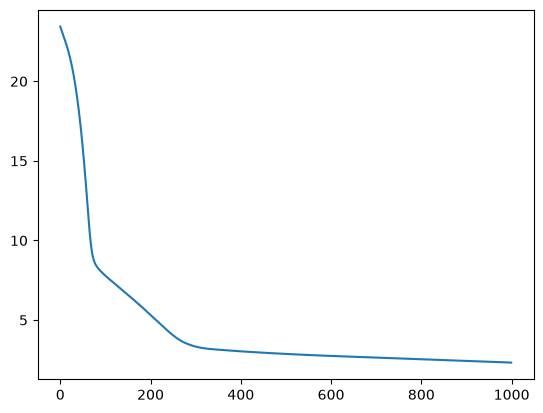

In [154]:
plt.plot(y_loss)